# 02 Model Scientific Interest

Canonical modeling notebook for yearly scientific interest.
This notebook computes SI, ranks future high-interest pathogen-antibiotic pairs, and generates focused plots.
Set `ANTIBIOTIC_ANALYSIS_LEVEL` to `"antibiotic"` for individual antibiotics, or to a column in `assets/antibiotic_coarsening_lookup.csv` such as `"Class"`.


In [1]:
%load_ext autoreload
%autoreload 2


In [2]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "amr").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "amr").exists():
    raise RuntimeError(f"Could not find repository root from {Path.cwd()}")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from amr.pipelines.si import (
    DEFAULT_DRIVER_SUMMARY_COLUMNS,
    DEFAULT_INTERESTING_SUMMARY_COLUMNS,
    build_si_analysis_paths,
    build_si_driver_analysis,
    build_yearly_si_dataset,
    filter_model_inputs_by_average_amr_publications,
    load_yearly_si_inputs,
    prepare_antibiotic_analysis_level,
    print_si_dataset_summary,
    rank_future_high_interest_pairs,
    save_category_driver_plots,
    save_interesting_si_plots,
    select_existing_columns,
    summarize_pair_publication_rates,
)


## Configuration


In [3]:
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "assets").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
OUTPUT_DIR = PROJECT_ROOT / "outputs"
PARQUET_OUTPUT_DIR = OUTPUT_DIR / "parquets"
PARQUET_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = PARQUET_OUTPUT_DIR

YEARLY_SCREENED_PATH = PARQUET_OUTPUT_DIR / "yearly_amr_screened_pairs.parquet"
UNIFIED_DECISIONS_PATH = PARQUET_OUTPUT_DIR / "yearly_amr_unified_decisions.parquet"
PATHOGEN_BG_PATH = PARQUET_OUTPUT_DIR / "pathogen_tiab_counts.parquet"
ANTIBIOTIC_BG_PATH = PARQUET_OUTPUT_DIR / "antibiotic_tiab_counts.parquet"
ANTIBIOTIC_COARSENING_PATH = PROJECT_ROOT / "assets" / "antibiotic_coarsening_lookup.csv"

ANTIBIOTIC_ANALYSIS_LEVEL = "Antibiotic" #Antibiotic,Class,Simplified categories,High level categories,Origin
SI_PATHS = build_si_analysis_paths(PROJECT_ROOT, ANTIBIOTIC_ANALYSIS_LEVEL)
YEARLY_SI_PATH = SI_PATHS["yearly_si"]
RANK_OUTPUT_PATH = SI_PATHS["rank_output"]
INTERESTING_OUTPUT_PATH = SI_PATHS["interesting_output"]
DRIVER_OUTPUT_PATH = SI_PATHS["driver_output"]
INTERESTING_PLOT_DIR = SI_PATHS["interesting_plot_dir"]
DRIVER_PLOT_DIR = SI_PATHS["driver_plot_dir"]

FIT_START_YEAR = 2000
FIT_END_YEAR = 2023
NUM_FUTURE_YEARS = 5

MIN_AVG_AMR_PUBLICATIONS_PER_YEAR = 5.0
MIN_CURRENT_PREDICTED_COUNT = 10
MIN_FUTURE_PREDICTED_COUNT = 10
MIN_SI_CHANGE = 0.05
MIN_POST_FIT_OBSERVED_YEARS = 1
MAX_POST_FIT_SI_ABS_PCT_ERROR_MEAN = 750.0
FALLBACK_TOP_N = 10

CATEGORY_INCLUDE_DECISIONS = ("yes", "uncertain")
DRIVER_LOOKBACK_YEARS = 5
MAX_DRIVER_PLOTS = 25
MAX_INTERESTING_PLOTS = 25
FIGURE_FORMAT = "pdf"
DISPLAY_PLOTS = True
MAX_DISPLAY_PLOTS = 10
FILL_MISSING_AMR_COUNTS_WITH_ZERO = True
PLOT_END_YEAR = FIT_END_YEAR + NUM_FUTURE_YEARS


## Load Canonical Inputs


In [4]:
yearly_screened_df, pathogen_bg_df, antibiotic_bg_df, unified_decisions_df = load_yearly_si_inputs(
    yearly_screened_path=YEARLY_SCREENED_PATH,
    pathogen_background_path=PATHOGEN_BG_PATH,
    antibiotic_background_path=ANTIBIOTIC_BG_PATH,
    unified_decisions_path=UNIFIED_DECISIONS_PATH,
)


yearly_screened rows: 411
pathogen bg rows: 135
antibiotic bg rows: 918
unified decision rows available for driver analysis: 5,365


## Prepare Antibiotic Analysis Level

This step optionally aggregates from individual antibiotics to a selected coarsening column before SI modeling.


In [5]:
yearly_screened_model_df, antibiotic_bg_model_df, unified_decisions_model_df, analysis_summary = prepare_antibiotic_analysis_level(
    yearly_screened_df=yearly_screened_df,
    antibiotic_background_df=antibiotic_bg_df,
    unified_decisions_df=unified_decisions_df,
    coarsening_path=ANTIBIOTIC_COARSENING_PATH,
    analysis_level=ANTIBIOTIC_ANALYSIS_LEVEL,
)

yearly_screened_model_df.head(10)


Antibiotic analysis level: individual antibiotic.
model yearly rows: 411
model pathogen-antibiotic rows: 30
model antibiotic values: 7
model antibiotic background rows: 918
model unified decision rows: 5,365


,pathogen,antibiotic,year,pmids,count
0,Clostridioides difficile,Amoxicillin,2010,"[19406247, 20518764]",2
1,Clostridioides difficile,Amoxicillin,2012,"[22710106, 23001653, 23072056]",3
2,Clostridioides difficile,Amoxicillin,2014,[24320797],1
3,Clostridioides difficile,Amoxicillin,2015,[24875330],1
4,Clostridioides difficile,Amoxicillin,2016,"[27130808, 27536994]",2
5,Clostridioides difficile,Amoxicillin,2017,"[27484050, 27521583]",2
6,Clostridioides difficile,Amoxicillin,2018,"[29689301, 29802886]",2
7,Clostridioides difficile,Amoxicillin,2019,"[30644987, 30761842, 31137766]",3
8,Clostridioides difficile,Amoxicillin/clavulanic-acid,2010,[19406247],1
9,Clostridioides difficile,Amoxicillin/clavulanic-acid,2012,[23072056],1


## Build Yearly SI Dataset


## Filter Low-Volume Pairs

Keep only pathogen-antibiotic pairs with enough screened AMR publications on average across the fitting window. The average includes years with zero publications.


In [6]:
yearly_screened_model_df, unified_decisions_model_df, pair_publication_rates = filter_model_inputs_by_average_amr_publications(
    yearly_screened_model_df=yearly_screened_model_df,
    unified_decisions_model_df=unified_decisions_model_df,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    min_avg_amr_publications_per_year=MIN_AVG_AMR_PUBLICATIONS_PER_YEAR,
)

summarize_pair_publication_rates(pair_publication_rates, head=30)


AMR publication filter: kept 8 / 30 pairs with >= 5 publications/year on average from 2000 to 2023.


,pathogen,antibiotic,fit_window_amr_publications,avg_amr_publications_per_year
26,Salmonella enterica,Ampicillin,639,26.625000
11,Klebsiella pneumoniae,Amikacin,376,15.666667
14,Klebsiella pneumoniae,Ampicillin,372,15.500000
12,Klebsiella pneumoniae,Amoxicillin,197,8.208333
8,Haemophilus influenzae,Ampicillin,169,7.041667
24,Salmonella enterica,Amoxicillin,151,6.291667
28,Salmonella enterica,Azithromycin,130,5.416667
6,Haemophilus influenzae,Amoxicillin,126,5.250000
13,Klebsiella pneumoniae,Amoxicillin/clavulanic-acid,99,4.125000
10,Haemophilus influenzae,Azithromycin,83,3.458333


In the next code cell, the notebook combines the screened yearly AMR counts with background publication counts to calculate a scientific-interest score for each pathogen-antibiotic-year. In simple terms, it estimates how much attention each pair is getting beyond what would be expected from general research activity alone, then saves those results for ranking and forecasting in later steps.


In [7]:
si_df, pooled_model, design_columns = build_yearly_si_dataset(
    yearly_screened_model_df,
    pathogen_bg_df,
    antibiotic_bg_model_df,
    output_path=YEARLY_SI_PATH,
)

print_si_dataset_summary(si_df)
si_df.head(10)


SI rows: 192
SI pairs: 8


,pathogen,antibiotic,year,pmids,count,bg_pathogen_n,bg_antibiotic_n,log_count,log_bg_pathogen_n,log_bg_antibiotic_n,expected_log_count_global,expected_count_global,SI
0,Haemophilus influenzae,Amoxicillin,2000,"[10729663, 10764967, 10770773, 10810209, 11001...",9,495,315,1.000000,2.695482,2.499687,0.600641,2.986952,0.399359
1,Haemophilus influenzae,Amoxicillin,2001,"[11320449, 11755441, 11980591]",3,522,368,0.602060,2.718502,2.567026,0.663038,3.602971,-0.060978
2,Haemophilus influenzae,Amoxicillin,2002,"[11751778, 12017369, 12077154, 12084002, 12384...",6,466,397,0.845098,2.669317,2.599883,0.651010,3.477238,0.194088
3,Haemophilus influenzae,Amoxicillin,2003,"[12697646, 12760861, 14521493, 14632101, 14663...",5,481,442,0.778151,2.683047,2.646404,0.692589,3.927074,0.085562
4,Haemophilus influenzae,Amoxicillin,2004,"[14726431, 14729759, 14732312, 15056440, 15081...",14,458,452,1.176091,2.661813,2.656098,0.684314,3.834087,0.491777
5,Haemophilus influenzae,Amoxicillin,2005,"[15591260, 15967638, 15980390, 19667702]",4,440,454,0.698970,2.644439,2.658011,0.673413,3.714258,0.025557
6,Haemophilus influenzae,Amoxicillin,2006,"[16133242, 16836856, 16842955, 16891323, 16922...",5,422,416,0.778151,2.626340,2.620136,0.634697,3.312180,0.143454
7,Haemophilus influenzae,Amoxicillin,2007,"[17334726, 17428889, 17597058, 17697316, 17908...",8,430,487,0.954243,2.634477,2.688420,0.687279,3.867202,0.266963
8,Haemophilus influenzae,Amoxicillin,2008,"[18280571, 18505850, 18931466, 19094865]",4,380,445,0.698970,2.580925,2.649335,0.622808,3.195738,0.076162
9,Haemophilus influenzae,Amoxicillin,2009,"[19246022, 19306715, 20071285, 20137709]",4,404,498,0.698970,2.607455,2.698101,0.674926,3.730711,0.024044


## Rank Reliable Future High-Interest Pairs


In [8]:
rank_df, interesting_df = rank_future_high_interest_pairs(
    si_df,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    min_current_predicted_count=MIN_CURRENT_PREDICTED_COUNT,
    min_future_predicted_count=MIN_FUTURE_PREDICTED_COUNT,
    min_si_change=MIN_SI_CHANGE,
    min_post_fit_observed_years=MIN_POST_FIT_OBSERVED_YEARS,
    max_post_fit_si_abs_pct_error_mean=MAX_POST_FIT_SI_ABS_PCT_ERROR_MEAN,
    fallback_top_n=FALLBACK_TOP_N,
    rank_output_path=RANK_OUTPUT_PATH,
    interesting_output_path=INTERESTING_OUTPUT_PATH,
    verbose=True,
)

select_existing_columns(
    interesting_df,
    DEFAULT_INTERESTING_SUMMARY_COLUMNS,
    head=30,
)


[1/8] ranking Haemophilus influenzae vs Amoxicillin
[2/8] ranking Haemophilus influenzae vs Ampicillin
[3/8] ranking Klebsiella pneumoniae vs Amikacin
[4/8] ranking Klebsiella pneumoniae vs Amoxicillin
[5/8] ranking Klebsiella pneumoniae vs Ampicillin
[6/8] ranking Salmonella enterica vs Amoxicillin
[7/8] ranking Salmonella enterica vs Ampicillin
[8/8] ranking Salmonella enterica vs Azithromycin


,pathogen,antibiotic,interest_score,si_change,current_predicted_count,future_predicted_count,post_fit_si_abs_pct_error_mean
0,Klebsiella pneumoniae,Amoxicillin,0.114807,0.200257,31.384397,99.998261,55.746778
1,Salmonella enterica,Azithromycin,0.085761,0.152790,23.050564,47.971011,34.280042
2,Klebsiella pneumoniae,Ampicillin,0.075469,0.132032,54.305022,140.515579,145.925297


## Explain Predicted SI Changes

This section uses the LLM category metadata from the unified abstract screen to describe which AMR paper types are driving the observed count curves behind the SI forecast. The analysis is descriptive: it explains category mix and recent changes, while the ranking itself remains based on the screened yearly AMR counts.


In [9]:
category_counts_df, interesting_with_drivers_df = build_si_driver_analysis(
    interesting_df=interesting_df,
    unified_decisions_df=unified_decisions_model_df,
    fit_end_year=FIT_END_YEAR,
    include_decisions=CATEGORY_INCLUDE_DECISIONS,
    lookback_years=DRIVER_LOOKBACK_YEARS,
    output_path=DRIVER_OUTPUT_PATH,
)

select_existing_columns(
    interesting_with_drivers_df,
    DEFAULT_DRIVER_SUMMARY_COLUMNS,
    head=30,
)


Saved SI driver explanations to /media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/parquets/yearly_si_driver_explanations.parquet


,pathogen,antibiotic,interest_score,si_change,current_predicted_count,future_predicted_count,driver_recent_total,driver_count_change,driver_dominant_category,driver_fastest_growing_category,driver_weak_signal_share,driver_manual_review_share
0,Klebsiella pneumoniae,Amoxicillin,0.114807,0.200257,31.384397,99.998261,109,70,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_PREVALENCE_SURVEILLANCE,0.0,0.880734
1,Salmonella enterica,Azithromycin,0.085761,0.152790,23.050564,47.971011,87,57,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_PREVALENCE_SURVEILLANCE,0.0,0.965517
2,Klebsiella pneumoniae,Ampicillin,0.075469,0.132032,54.305022,140.515579,202,130,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_PREVALENCE_SURVEILLANCE,0.0,0.782178


## Plot Category Driver Curves


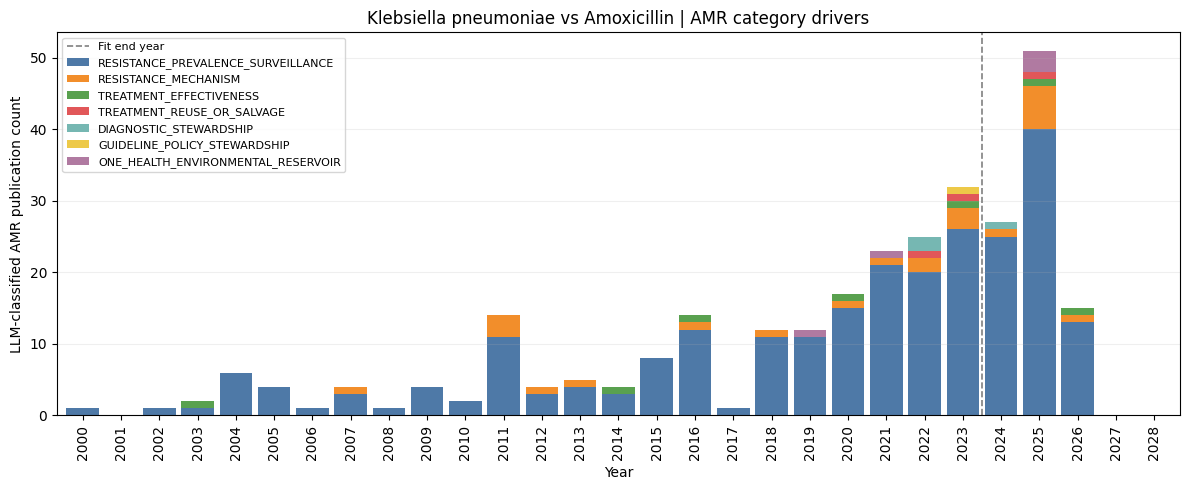

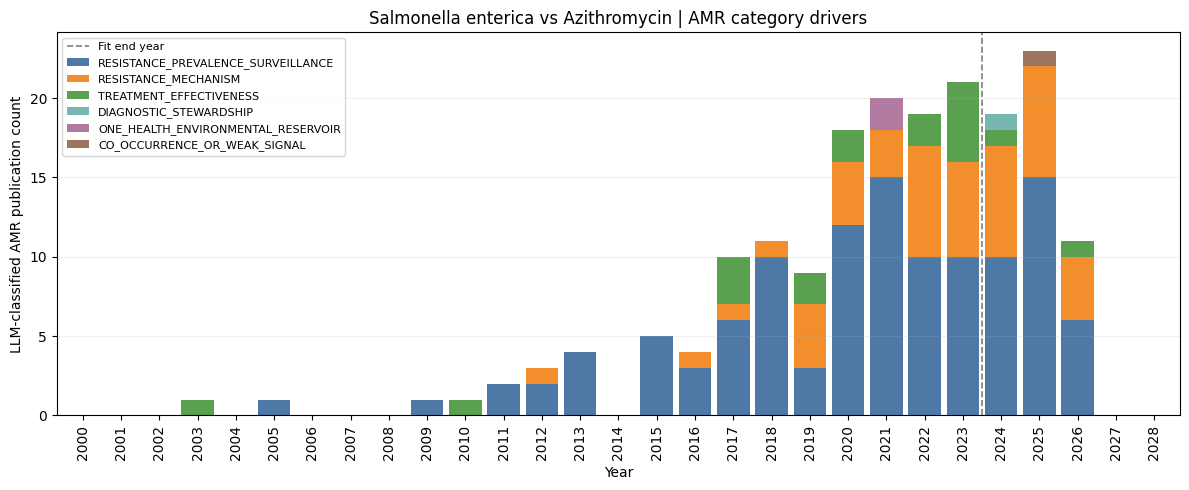

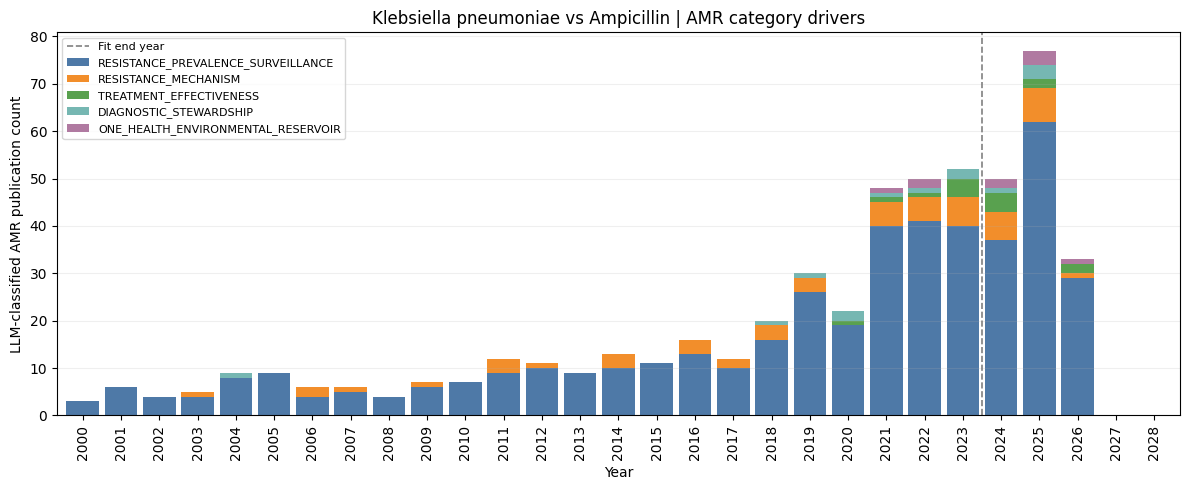

Saved 3 category driver plots to /media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/interesting_yearly_si_driver_plots
Displayed 3 category driver plots inline.


In [10]:
saved_driver_plots = save_category_driver_plots(
    category_counts_df=category_counts_df,
    interesting_df=interesting_df,
    output_dir=DRIVER_PLOT_DIR,
    start_year=FIT_START_YEAR,
    end_year=PLOT_END_YEAR,
    fit_end_year=FIT_END_YEAR,
    max_plots=MAX_DRIVER_PLOTS,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)


## Plot Top Interesting Pairs


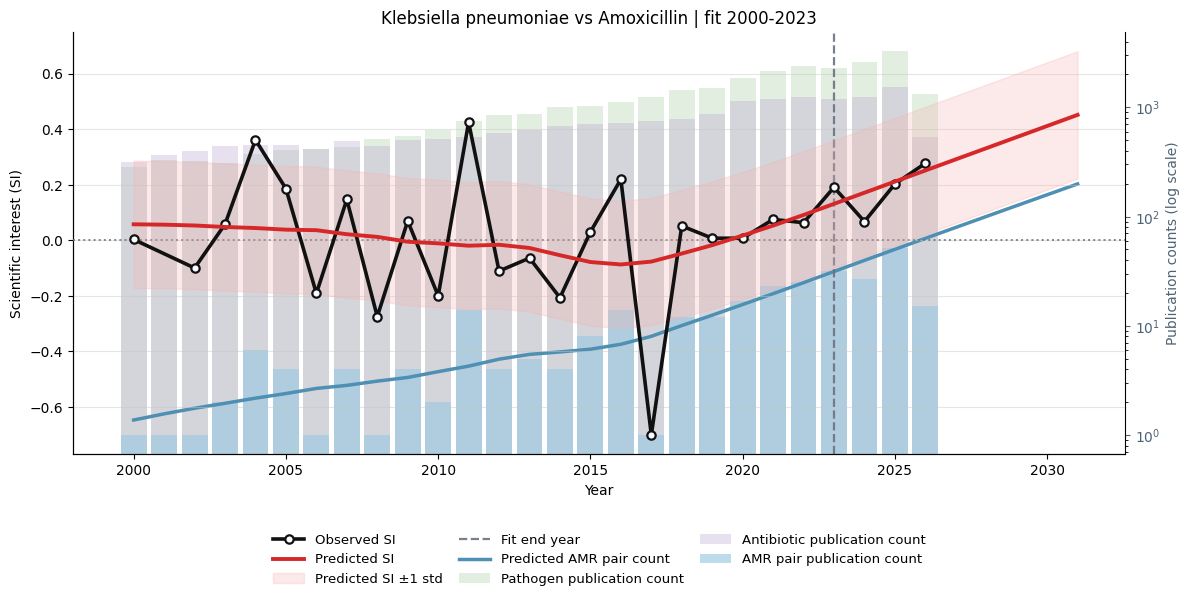

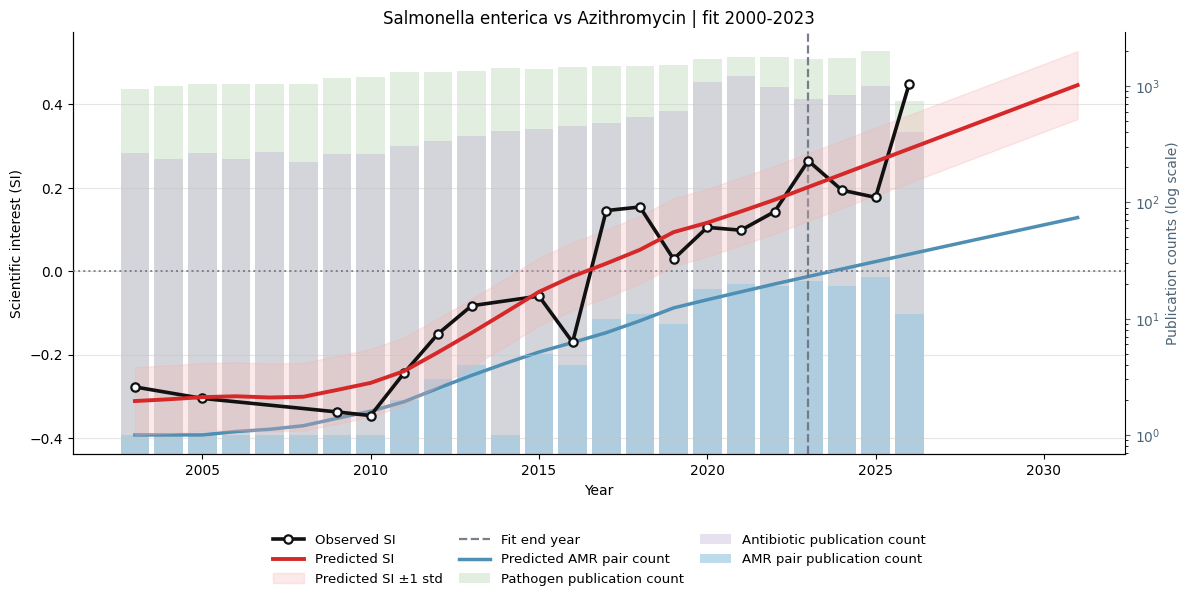

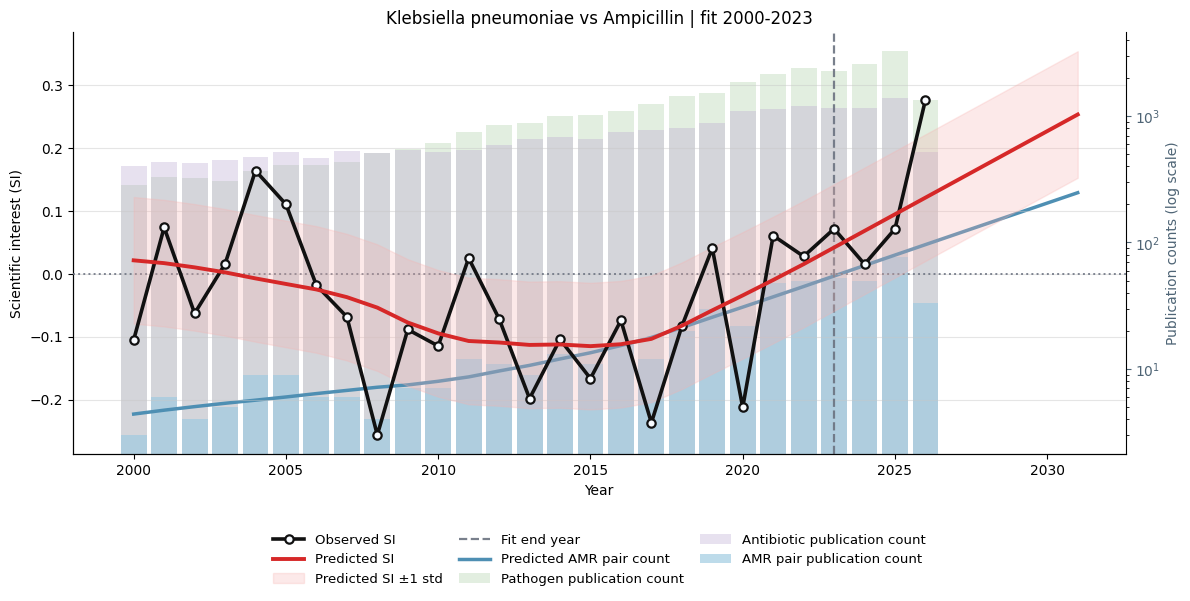

Saved 3 plots to /media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/interesting_yearly_si_plots
Displayed 3 plots inline.


In [11]:
saved_interesting_plots = save_interesting_si_plots(
    si_df=si_df,
    interesting_df=interesting_df,
    output_dir=INTERESTING_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=MAX_INTERESTING_PLOTS,
    loess_frac=0.6,
    loess_degree=1,
    tail_damping_years=None,
    fill_missing_amr_counts_with_zero=FILL_MISSING_AMR_COUNTS_WITH_ZERO,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)
